# KAN on Buchwald-Hartwig amination with the Science 2018 DFT descriptors

**Source.** Ahneman, Estrada, Lin, Dreher, Doyle, *Science* **2018**, *360*, 186-190
(DOI 10.1126/science.aar5169). The DFT descriptor table is the one shipped with the `edbo`
package (`science_dft.csv`, 3955 reactions). The component names come from the authors' own
`rxnpredict` repository and are matched back onto the descriptor table in section 1.

**Reaction.** Pd-catalyzed C-N coupling of 15 aryl halides (five scaffolds as the chloride,
bromide and iodide) with 4-methylaniline, four biaryl phosphine ligands (XPhos, *t*-BuXPhos,
*t*-BuBrettPhos, AdBrettPhos), three organic bases (P2Et, BTMG, MTBD) and 22 isoxazole additives,
run in 1536-well plates.

**The paper's finding.** A random forest on these descriptors predicted yield far better than a
linear model, and the additive descriptors carried much of the signal. Follow-up experiments
showed the isoxazole additives can consume the Pd(0) catalyst by oxidative addition into the
N-O bond, so those descriptors are reporting catalyst poisoning rather than the desired coupling.

**Descriptors used here.** The first chemistry notebook in this series used 2D RDKit descriptors
and could not tell one descriptor of a component from another. This one uses the paper's DFT
descriptors, 24 of them chosen in advance to cover each component's electronics (HOMO, LUMO,
charges, NMR shifts), size (volume) and polarity (dipole). Collinearity inside a component
remains: four ligands and three bases cannot support more than three and two independent effects.

**Units.** The authors standardized `science_dft.csv` column by column, so every descriptor is in
standard deviations, not in ppm, hartree or cubic angstrom. Section 1 checks this. Curves in this
notebook are therefore read as "how the prediction moves per standard deviation of the
descriptor", and the component identities recovered below carry the chemistry.

**Target.** Yield in percent, regression. Success for the threshold rules: above 20 % yield.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Partial effects with fold envelopes.** One-descriptor response curves of the KAN in the
   descriptor's own units, with the linear baseline on the same grid and the envelope of five
   refits. A shape that changes from fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    sensitivity,
    threshold_rules,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the DFT descriptor table and recover the component names

The descriptor table has no names, but the authors published the per-molecule descriptor tables
and the name lists separately. Standardization is monotone per column, so the *k*-th smallest
value of a descriptor in the dataset belongs to the molecule with the *k*-th smallest value in the
per-molecule table. The mapping built from one descriptor is checked against two others: if it is
right, every reaction with molecule M's value of descriptor A also carries M's value of B.


In [2]:
URL = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/aryl_amination/science_dft.csv"
RXN = "https://raw.githubusercontent.com/doylelab/rxnpredict/master/"
raw = pd.read_csv(URL)
CHOSEN = {
    "additive": [
        "additive_E_LUMO", "additive_E_HOMO", "additive_.C3_NMR_shift", "additive_.C4_NMR_shift",
        "additive_.C5_NMR_shift", "additive_.N1_electrostatic_charge", "additive_.O1_electrostatic_charge",
        "additive_dipole_moment", "additive_molecular_volume",
    ],
    "aryl halide": [
        "aryl_halide_E_LUMO", "aryl_halide_E_HOMO", "aryl_halide_.C1_NMR_shift",
        "aryl_halide_.C1_electrostatic_charge", "aryl_halide_.C4_NMR_shift", "aryl_halide_.H2_NMR_shift",
        "aryl_halide_dipole_moment", "aryl_halide_molecular_volume", "aryl_halide_hardness",
    ],
    "base": ["base_E_HOMO", "base_.N1_electrostatic_charge", "base_molecular_volume"],
    "ligand": ["ligand_.P1_electrostatic_charge", "ligand_dipole_moment", "ligand_.C1_NMR_shift"],
}  # fmt: skip
COMPONENT = {c: comp for comp, cols in CHOSEN.items() for c in cols}
X_df = raw[list(COMPONENT)].copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"

stats = X_df.agg(["mean", "std"]).T
print(f"Descriptor means are {stats['mean'].abs().max():.3f} or less and standard deviations "
      f"{stats['std'].min():.3f} to {stats['std'].max():.3f}: the table is standardized.")  # fmt: skip


def recover_names(key_col, table_col, table, names, checks):
    """Map each dataset level of key_col to a molecule name, then verify on other descriptors."""
    rank = np.argsort(np.argsort(table[table_col].to_numpy()))
    levels = np.sort(raw[key_col].unique())
    assert len(levels) == len(table), f"{len(levels)} levels vs {len(table)} molecules"
    mapping = {i: levels[rank[i]] for i in range(len(table))}
    for s_col, t_col in checks:
        lv, rk = np.sort(raw[s_col].unique()), np.argsort(np.argsort(table[t_col].to_numpy()))
        for i in range(len(table)):
            seen = raw.loc[raw[key_col] == mapping[i], s_col].unique()
            assert len(seen) == 1 and np.isclose(seen[0], lv[rk[i]]), f"{t_col} disagrees for {names[i]}"
    return {mapping[i]: names[i] for i in range(len(table))}


def name_list(stem):
    n = pd.read_csv(RXN + f"smiles/{stem}-list.csv")
    return n["name"].tolist()[: len(pd.read_csv(RXN + f"R/{stem}.csv"))]


def smiles_list(stem, col):
    n = pd.read_csv(RXN + f"smiles/{stem}-list.csv")
    return dict(zip(n["name"], n[col]))


tables = {s: pd.read_csv(RXN + f"R/{s}.csv") for s in ["aryl_halide", "additive", "base", "ligand"]}
raw["aryl_halide"] = raw["aryl_halide_.C1_NMR_shift"].map(
    recover_names("aryl_halide_.C1_NMR_shift", "aryl_halide_*C1_NMR_shift", tables["aryl_halide"], name_list("aryl_halide"),
                  [("aryl_halide_.C4_NMR_shift", "aryl_halide_*C4_NMR_shift"), ("aryl_halide_E_LUMO", "aryl_halide_E_LUMO"),
                   ("aryl_halide_molecular_volume", "aryl_halide_molecular_volume")])
)  # fmt: skip
raw["additive"] = raw["additive_.C3_NMR_shift"].map(
    recover_names("additive_.C3_NMR_shift", "additive_*C3_NMR_shift", tables["additive"], name_list("additive"),
                  [("additive_.C4_NMR_shift", "additive_*C4_NMR_shift"), ("additive_E_LUMO", "additive_E_LUMO")])
)  # fmt: skip
raw["base"] = raw["base_E_HOMO"].map(
    recover_names("base_E_HOMO", "base_E_HOMO", tables["base"], name_list("base"),
                  [("base_molecular_volume", "base_molecular_volume"), ("base_.N1_electrostatic_charge", "base_*N1_electrostatic_charge")])
)  # fmt: skip
raw["ligand"] = raw["ligand_dipole_moment"].map(
    recover_names("ligand_dipole_moment", "ligand_dipole_moment", tables["ligand"], name_list("ligand"),
                  [("ligand_.C1_NMR_shift", "ligand_*C1_NMR_shift"), ("ligand_.P1_electrostatic_charge", "ligand_*P1_electrostatic_charge")])
)  # fmt: skip
raw["halide"] = np.select([raw.aryl_halide.str.contains("iodo"), raw.aryl_halide.str.contains("bromo")], ["I", "Br"], "Cl")

# The scaffold is the aryl halide minus its halogen: the names are written inconsistently
# ("1-ethyl-4-iodobenzene" but "1-bromo-4-ethylbenzene"), so take it from the SMILES.
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")
AH_SMILES = smiles_list("aryl_halide", "Aryl_halide_SMILES")


def scaffold_of(name):
    mol = Chem.MolFromSmiles(AH_SMILES[name])
    edit = Chem.RWMol(mol)
    for atom in list(edit.GetAtoms()):
        if atom.GetSymbol() in ("Cl", "Br", "I"):
            edit.RemoveAtom(atom.GetIdx())
    return Chem.MolToSmiles(edit.GetMol())


SCAFFOLD_NAME = {
    "COc1ccc([H])cc1": "4-methoxyphenyl", "COc1ccccc1": "4-methoxyphenyl",
    "CCc1ccccc1": "4-ethylphenyl", "FC(F)(F)c1ccccc1": "4-(trifluoromethyl)phenyl",
    "c1ccncc1": "pyridin-3-yl", "c1ccccn1": "pyridin-2-yl",
}  # fmt: skip
raw["scaffold"] = raw.aryl_halide.map(lambda n: SCAFFOLD_NAME.get(scaffold_of(n), scaffold_of(n)))
print("Names recovered and verified against two further descriptors each.")
print(f"{len(raw)} reactions: {raw.aryl_halide.nunique()} aryl halides, {raw.additive.nunique()} additives, "
      f"{raw.base.nunique()} bases ({', '.join(sorted(raw.base.unique()))}), {raw.ligand.nunique()} ligands "
      f"({', '.join(sorted(raw.ligand.unique()))}).")  # fmt: skip


Dropped constant descriptors: []
Descriptor means are 0.025 or less and standard deviations 0.994 to 1.005: the table is standardized.


Names recovered and verified against two further descriptors each.
3955 reactions: 15 aryl halides, 22 additives, 3 bases (BTMG, MTBD, P2Et), 4 ligands (AdBrettPhos, XPhos, t-BuBrettPhos, t-BuXPhos).


3955 reactions, 24 descriptors. Target: yield (%) (regression).
Success for the threshold rules: yield above 20 % (59% of reactions).


,Component,Distinct,Min,Max
additive_E_LUMO,additive,22,-1.393,1.754
additive_E_HOMO,additive,22,-1.537,1.817
additive_.C3_NMR_shift,additive,22,-1.627,2.321
additive_.C4_NMR_shift,additive,22,-2.551,1.868
additive_.C5_NMR_shift,additive,20,-1.843,1.676
additive_.N1_electrostatic_charge,additive,22,-1.376,2.405
additive_.O1_electrostatic_charge,additive,19,-2.324,2.438
additive_dipole_moment,additive,22,-1.518,2.174
additive_molecular_volume,additive,22,-1.389,2.679
aryl_halide_E_LUMO,aryl halide,15,-3.705,0.531


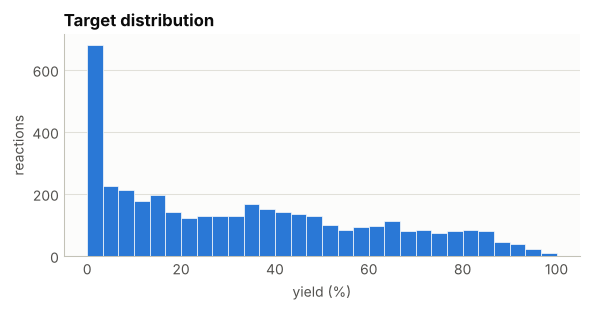

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?


Model                  r2               other
MLR                    0.466 ± 0.029   16.019 ± 0.369 (mae)
Random Forest          0.910 ± 0.014   5.497 ± 0.306 (mae)
Gradient Boosting      0.914 ± 0.007   5.861 ± 0.137 (mae)
KAN                    0.897 ± 0.011   6.444 ± 0.148 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.0168 ± 0.0083, KAN better in 0/15, Wilcoxon p = 6.1e-05
(228 s)


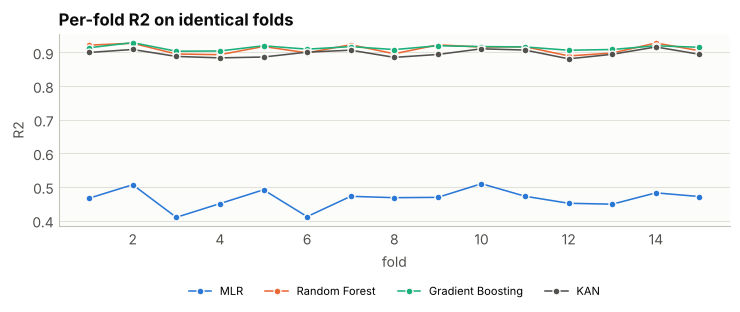

In [4]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3)


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 3164 train / 791 test


,Test R2,Test MAE
Model,,
MLR,0.467,16.477
Random Forest,0.922,5.195
Gradient Boosting,0.912,6.068
KAN,0.901,6.350


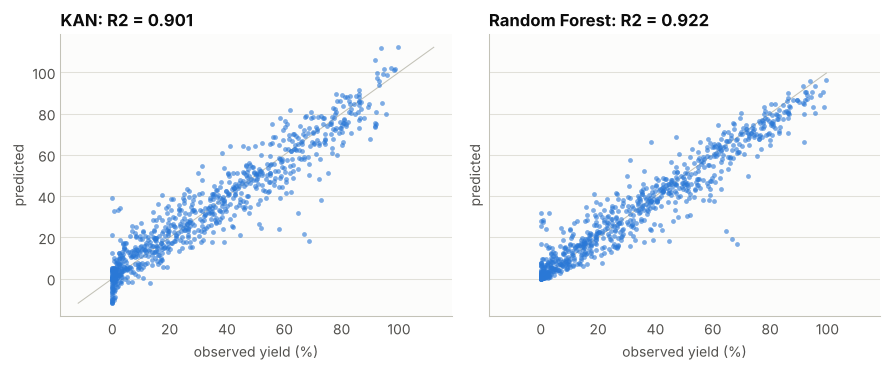

In [5]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.592
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,aryl_halide_.H2_NMR_shift,-0.693,0.707,0.697,0.800,0.650
1,aryl_halide_.C1_NMR_shift,0.416,0.667,0.633,0.825,0.483
2,aryl_halide_E_LUMO,0.419,0.659,0.707,0.689,0.919
3,aryl_halide_.C4_NMR_shift,-0.011,0.637,0.590,0.833,0.385
4,additive_.C3_NMR_shift,0.146,0.630,0.633,0.708,0.647
5,aryl_halide_molecular_volume,0.801,0.619,0.570,0.814,0.355
6,additive_.C4_NMR_shift,-0.037,0.612,0.625,0.684,0.679
7,aryl_halide_.C1_electrostatic_charge,0.810,0.606,0.547,0.853,0.284
8,aryl_halide_dipole_moment,0.958,0.606,0.547,0.853,0.284
9,additive_molecular_volume,-0.031,0.598,0.588,0.695,0.541


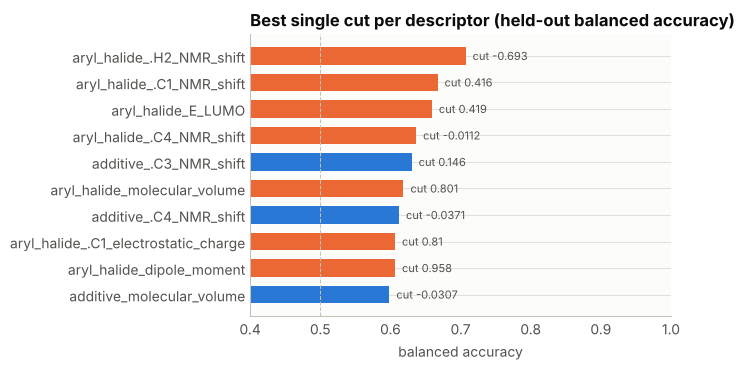

In [6]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Partial effects with fold envelopes

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors get a response curve in their own units
(the other descriptors at their mean), the linear baseline on the same grid, and the envelope of
five refits on disjoint folds. The support strip along the bottom shows where the data are.


,Feature,Component,Sensitivity
0,aryl_halide_molecular_volume,aryl halide,67.2532
1,aryl_halide_dipole_moment,aryl halide,26.4246
2,aryl_halide_E_LUMO,aryl halide,24.4856
3,aryl_halide_.C1_electrostatic_charge,aryl halide,22.3698
4,ligand_.C1_NMR_shift,ligand,15.9962
5,additive_.O1_electrostatic_charge,additive,15.6547
6,additive_.C3_NMR_shift,additive,15.0650
7,aryl_halide_E_HOMO,aryl halide,14.6609
8,aryl_halide_.C4_NMR_shift,aryl halide,13.3263
9,additive_E_HOMO,additive,12.5565


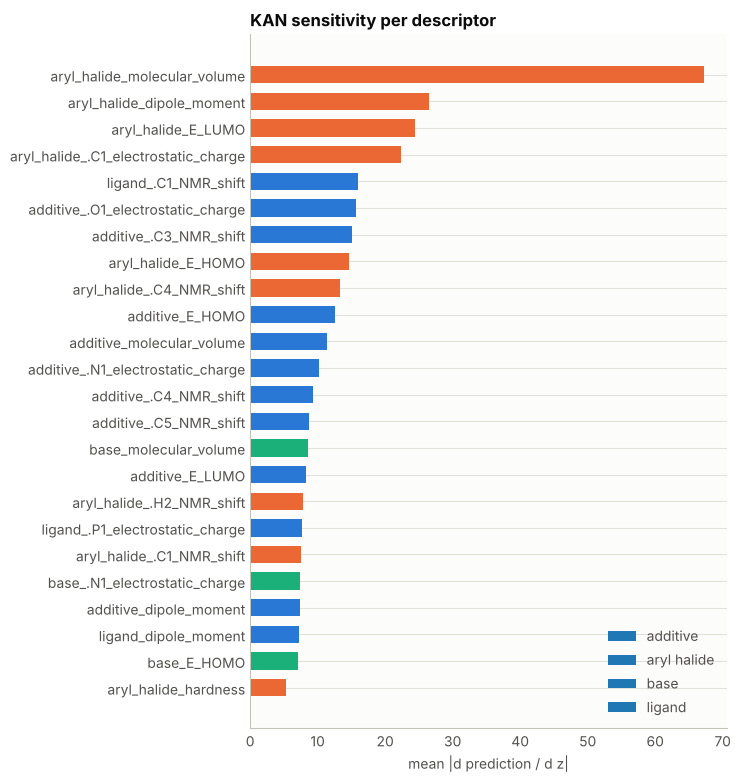

17 descriptors with at least 5 distinct values; 7 with fewer, shown as levels below.


fold envelopes: 55 s


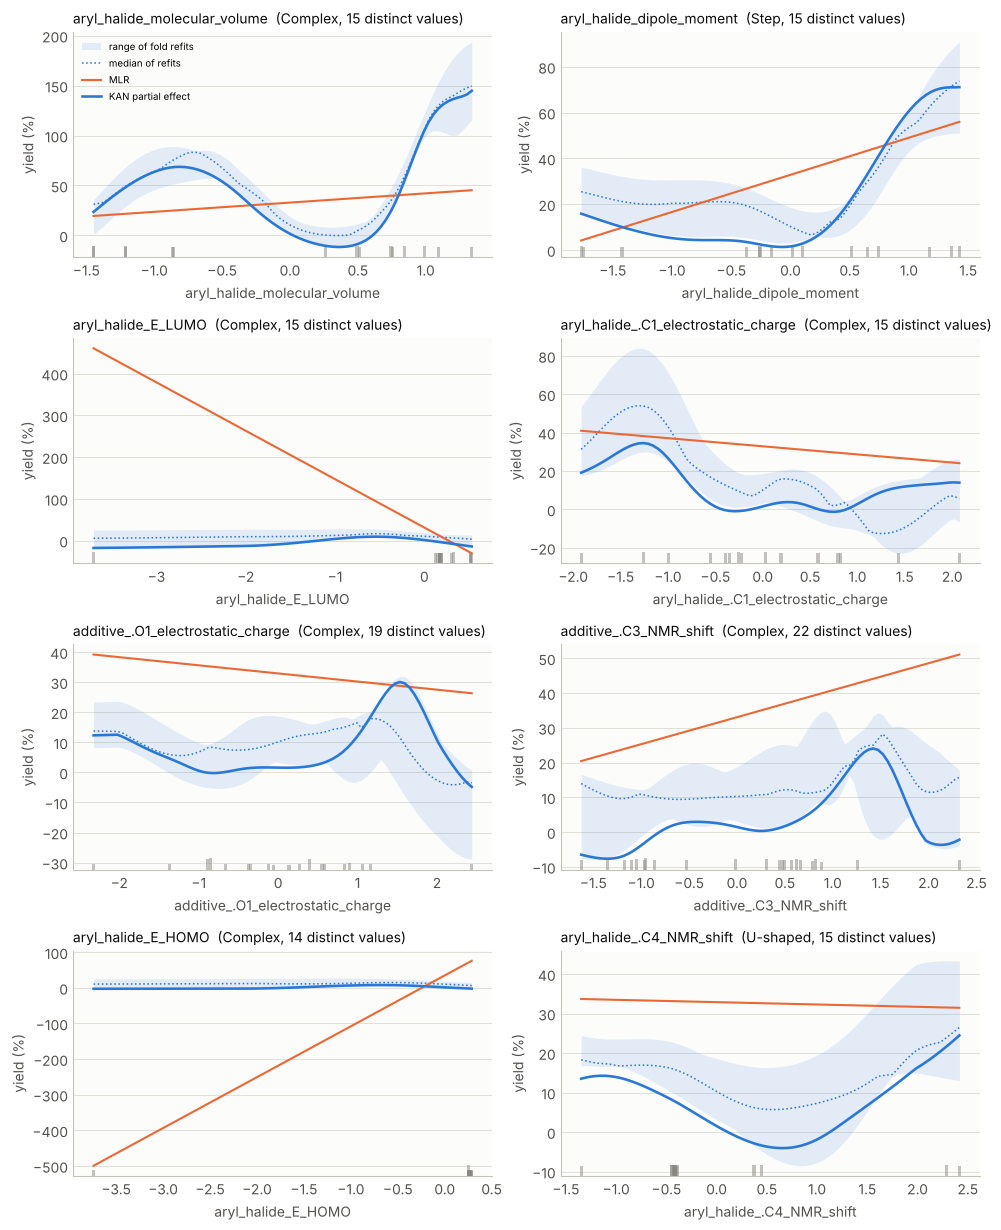

In [7]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in the next cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
effects = partial_effects(
    kan, X[idx_tr], feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
t0 = time.time()
effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=Y_LABEL)
    ax.set_title(f"{f}  ({effects[f].shape(scale=y.std() if TASK == 'regression' else 1.0)[0]}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
for ax in np.ravel(axes)[1:TOP_K]:  # one legend is enough
    if ax.get_legend():
        ax.get_legend().remove()
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


In [8]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,aryl_halide_hardness,aryl halide,-0.277,1319,35.880,35.670
1,aryl_halide_hardness,aryl halide,-0.262,2372,32.332,32.203
2,aryl_halide_hardness,aryl halide,3.741,264,25.894,25.770
3,base_E_HOMO,base,-1.247,1317,30.836,30.793
4,base_E_HOMO,base,0.046,1318,41.451,41.019
5,base_E_HOMO,base,1.201,1320,26.976,27.096
6,base_.N1_electrostatic_charge,base,-0.890,1317,30.836,30.793
7,base_.N1_electrostatic_charge,base,-0.507,1320,26.976,27.096
8,base_.N1_electrostatic_charge,base,1.397,1318,41.451,41.019
9,base_molecular_volume,base,-0.939,1318,41.451,41.019


Observed spread across the levels of each few-level descriptor:
Feature
ligand_dipole_moment               20.9
ligand_.P1_electrostatic_charge    20.9
ligand_.C1_NMR_shift               20.9
base_.N1_electrostatic_charge      14.5
base_E_HOMO                        14.5
base_molecular_volume              14.5
aryl_halide_hardness               10.0


In [9]:
# Shape of the single fit, and whether the five refits agree on it. A curve whose
# range is under 5 % of the target's spread is "Constant" whatever its wiggles.
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, note = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: single fit {r.Shape}; folds {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Fold shapes
0,aryl_halide_molecular_volume,aryl halide,Complex,0.973,1.0,0.206,"Complex, Complex, Complex, Complex, Complex"
1,aryl_halide_dipole_moment,aryl halide,Step,0.664,0.8,0.308,"Step, Step, Step, Complex, Step"
2,aryl_halide_E_LUMO,aryl halide,Complex,0.671,0.8,2.327,"Complex, Step, Complex, Complex, Complex"
3,aryl_halide_.C1_electrostatic_charge,aryl halide,Complex,0.857,0.8,0.474,"Complex, Complex, Step, Complex, Complex"
4,additive_.O1_electrostatic_charge,additive,Complex,0.964,0.6,0.943,"Complex, Step, Step, Complex, Complex"
5,additive_.C3_NMR_shift,additive,Complex,0.845,1.0,1.136,"Complex, Complex, Complex, Complex, Complex"
6,aryl_halide_E_HOMO,aryl halide,Complex,0.710,0.8,2.743,"Complex, Step, Complex, Complex, Complex"
7,aryl_halide_.C4_NMR_shift,aryl halide,U-shaped,0.991,0.2,0.937,"U-shaped, Step, Step, Complex, Complex"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
  aryl_halide_molecular_volume: Complex
  aryl_halide_dipole_moment: Step
  aryl_halide_.C1_electrostatic_charge: Complex
Shapes that do not:
  aryl_halide_E_LUMO: single fit Complex; folds Complex, Step, Complex, Complex, Complex
  additive_.O1_electrostatic_charge: single fit Complex; folds Complex, Step, Step, Complex, Complex
  additive_.C3_NMR_shift: single fit Complex; folds Complex, Complex, Complex, Complex, Complex
  aryl_halide_E_HOMO: single fit Complex; folds Complex, Step, Complex, Complex, Complex
  aryl_halide_.C4_NMR_shift: single fit U-shaped; folds U-shaped, Step, Step, Complex, Complex


## 5. Check against the chemistry

With the names recovered, two things can be checked that no model is needed for. Oxidative
addition of Pd(0) into a carbon-halogen bond goes I > Br > Cl, so the same scaffold should give
higher yields as the halide gets heavier. And the paper's additive effect is catalyst poisoning,
so the additive ranking is a property of the isoxazole, not of the coupling partners.


,mean,count
halide,,
I,45.7,1318
Br,38.4,1319
Cl,15.1,1318


Mean yield per scaffold and halide (every row should rise left to right):


halide,Cl,Br,I
scaffold,,,
4-(trifluoromethyl)phenyl,12.5,26.9,33.7
4-ethylphenyl,3.9,43.5,52.6
4-methoxyphenyl,1.9,25.9,32.5
pyridin-3-yl,28.7,47.7,54.9


Scaffolds with Cl < Br: 4/4; with Br < I: 4/4


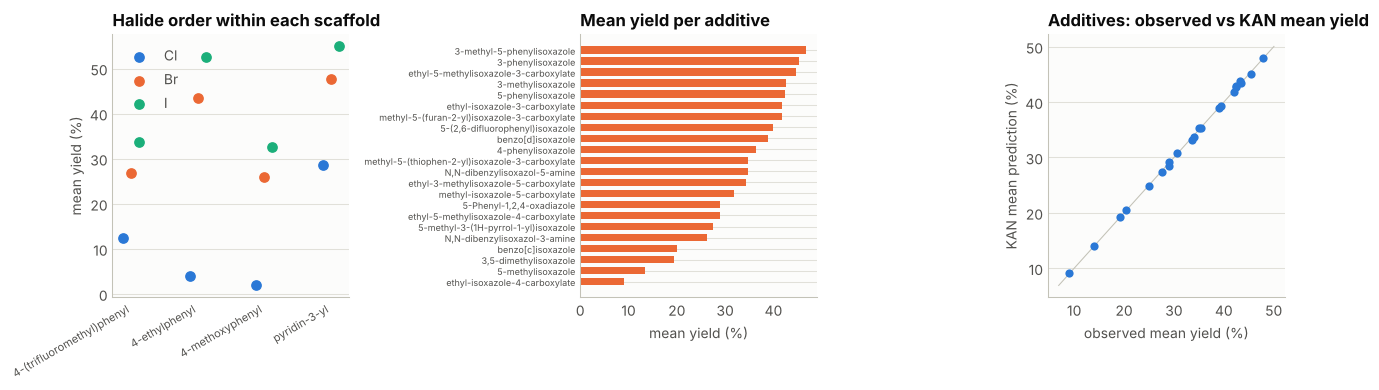

Spearman correlation of additive mean yield with the C3 shift: 0.67
The KAN reproduces the 22 additive means to a mean absolute error of 0.2 points.
Mean yield by ligand and base:


base,BTMG,MTBD,P2Et
ligand,,,
AdBrettPhos,29.2,44.4,27.0
XPhos,19.4,22.2,18.9
t-BuBrettPhos,35.2,47.9,29.6
t-BuXPhos,39.6,51.3,32.4


In [10]:
order = raw.groupby("halide")["yield"].agg(["mean", "count"]).reindex(["I", "Br", "Cl"]).round(1)
display(order)
piv = raw.pivot_table(index="scaffold", columns="halide", values="yield", aggfunc="mean")[["Cl", "Br", "I"]].round(1)
print("Mean yield per scaffold and halide (every row should rise left to right):")
display(piv)
print(f"Scaffolds with Cl < Br: {(piv.Cl < piv.Br).sum()}/{len(piv)}; with Br < I: {(piv.Br < piv['I']).sum()}/{len(piv)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ax = axes[0]
style_axes(ax)
for k, h in enumerate(["Cl", "Br", "I"]):
    ax.scatter(np.arange(len(piv)) + 0.12 * (k - 1), piv[h], s=45, color=SERIES[k], label=h, zorder=3)
ax.set_xticks(np.arange(len(piv)))
ax.set_xticklabels(piv.index, rotation=30, ha="right", fontsize=8)
ax.legend(frameon=False, fontsize=8, title=None)
finish_axes(ax, "Halide order within each scaffold", "", "mean yield (%)")

ax = axes[1]
style_axes(ax)
add = raw.groupby("additive").agg(x=("additive_.C3_NMR_shift", "first"), m=("yield", "mean")).sort_values("m")
ax.barh(np.arange(len(add)), add.m, color=SERIES[1], height=0.7, linewidth=0)
ax.set_yticks(np.arange(len(add)))
ax.set_yticklabels(add.index, fontsize=6.5)
finish_axes(ax, "Mean yield per additive", "mean yield (%)", "")

ax = axes[2]
style_axes(ax)
mm = model_means(raw.additive).join(add.x.rename("C3_shift"))
lim = [min(mm.observed.min(), mm.predicted.min()) - 2, max(mm.observed.max(), mm.predicted.max()) + 2]
ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
ax.scatter(mm.observed, mm.predicted, s=35, color=SERIES[0], linewidths=0, zorder=3)
finish_axes(ax, "Additives: observed vs KAN mean yield", "observed mean yield (%)", "KAN mean prediction (%)")
plt.tight_layout()
plt.show()

print(f"Spearman correlation of additive mean yield with the C3 shift: {add.m.corr(add.x, method='spearman'):.2f}")
print(f"The KAN reproduces the 22 additive means to a mean absolute error of {np.abs(mm.observed - mm.predicted).mean():.1f} points.")
print("Mean yield by ligand and base:")
display(raw.pivot_table(index="ligand", columns="base", values="yield", aggfunc="mean").round(1))


### Reading

Two things the model is not needed for, recovered from the named data, and one thing the
descriptor table cannot support.

**The halide order is exact.** Mean yield is 45.7 % for the iodides, 38.4 % for the bromides and
15.1 % for the chlorides, and within every one of the four scaffolds yield rises from chloride to
bromide to iodide without exception. That is the oxidative addition reactivity order, reproduced
across 3955 reactions. It is also the reason the aryl halide descriptors dominate the sensitivity
ranking: those descriptors are carrying the halogen.

**The additives span 9 to 47 % mean yield.** The worst are ethyl-isoxazole-4-carboxylate (9.0 %),
5-methylisoxazole (13.4 %) and 3,5-dimethylisoxazole (19.4 %); the best are 3-methyl-5-phenyl-
isoxazole (46.7 %) and 3-phenylisoxazole (45.3 %). The additive mean yield correlates with the
C3 NMR shift at Spearman 0.67, and the KAN reproduces all 22 additive means to a mean absolute
error of 0.2 points, so the model does carry the additive identity even where no single curve
can show it. The paper traced this to Pd insertion into the isoxazole N-O bond,
which consumes the catalyst, so these descriptors report how fast the additive destroys the
catalyst rather than anything about the coupling itself.

**Three and four level components cannot have single-descriptor curves.** The level table makes
this concrete: the three base descriptors (HOMO energy, N1 charge, molecular volume) produce
exactly the same three group means, 41.5, 30.8 and 27.0 %, because each is a relabelling of the
same three bases. Any curve drawn through one of them is an arbitrary assignment of one base
effect to one descriptor. The same holds for the four ligands, where the spread across levels is
20.9 points. Read the level table, not a curve.

**Models.** Gradient boosting and the random forest reach cross-validated R2 0.914 and 0.910
against 0.897 for the KAN and 0.466 for the linear model; the KAN loses in 15 folds of 15. The
gap between the linear model and the rest is the real result, and it is the paper's: yield here
is not additive in these descriptors.

**One caution on units.** The published descriptor table is standardized column by column, so
every number in this notebook's curves is in standard deviations, not ppm or hartree. The
notebook checks this in section 1 before reading anything from the axes.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


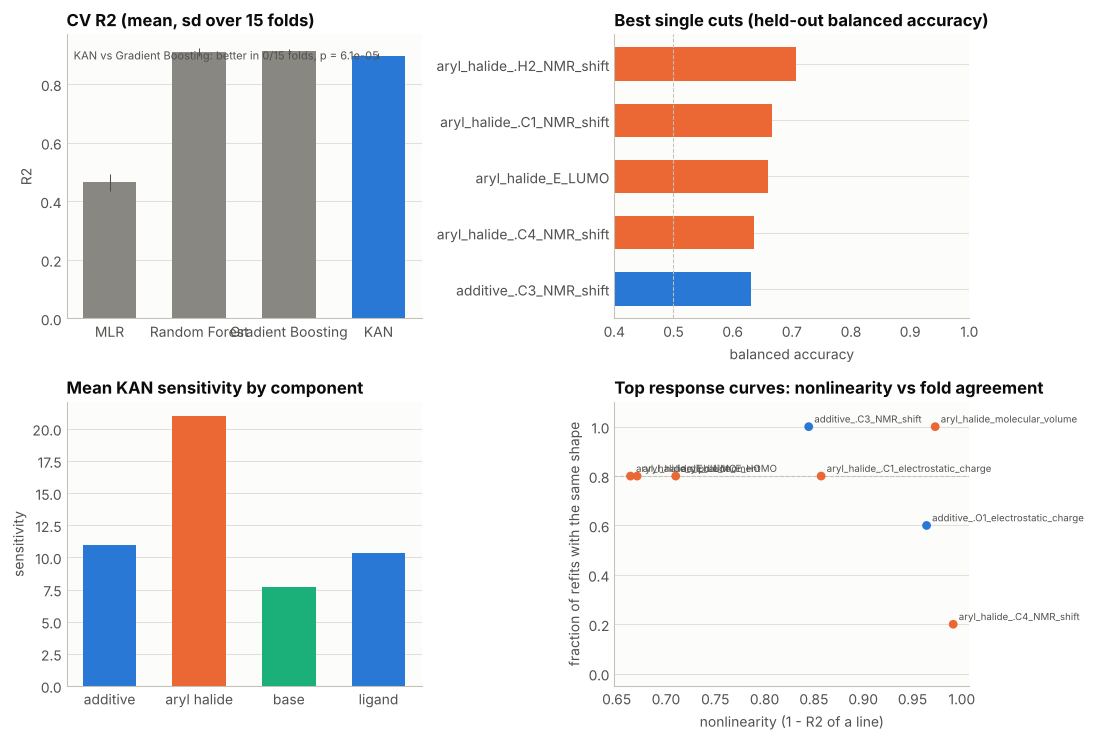

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
ax.scatter(stab["Nonlinearity"], stab["Fold agreement"], s=40, color=[COMP_COLOR[c] for c in stab.Component], linewidths=0, zorder=3)
for _, r in stab.iterrows():
    ax.annotate(r.Feature, (r.Nonlinearity, r["Fold agreement"]), fontsize=7, color=INK_2, xytext=(4, 3), textcoords="offset points")
ax.axhline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_ylim(-0.05, 1.1)
finish_axes(ax, "Top response curves: nonlinearity vs fold agreement", "nonlinearity (1 - R2 of a line)", "fraction of refits with the same shape")
plt.tight_layout()
plt.show()
